In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from tqdm import tqdm

In [2]:
def make_skew_symmetric(n):
    A = np.random.randn(n, n)
    return A - A.T

def make_positive_definite(n):
    A = np.random.randn(n, n)
    return A.T @ A

def rnn_step(z, U, W):
    norm_z = np.linalg.norm(z)
    return U @ z - (norm_z**2 - 1) * (W @ z)

def simulate(z0, U, W, dt, T):
    steps = int(T/dt)
    z = z0.copy()
    traj = np.zeros((steps, len(z0)))
    traj[0] = z
    for t in range(1, steps):
        z = z + dt * rnn_step(z, U, W)
        traj[t] = z
    return traj

def exponential_map(U, t, v):
    return scipy.linalg.expm(U * t) @ v

np.random.seed(0)

n = 128
U = make_skew_symmetric(n)
W = make_positive_definite(n)

dt = 5e-5
T = 0.03
steps = int(T/dt)
print(f"Simulation steps: {steps}")
times = np.arange(steps) * dt
eps = 1e-4
num_traj = 100

all_exp_devs = []
all_zstar_devs = []
all_energies = []
all_tstar = []
# run

for k in tqdm(range(num_traj)):
    z0 = np.random.uniform(-1, 1, n)*0.1
    z = simulate(z0, U, W, dt, T)

    # energy    
    energy = (np.linalg.norm(z, axis=1)**2 - 1)**2
    all_energies.append(energy)
    # find z*
    energy_mask = energy < eps
    if not np.any(energy_mask):
        print("No convergence to attractor")
        continue
    z_star = z[energy_mask][0] # first point on attractor
    t_star = times[energy_mask][0] # time of first point on attractor
    # compute deviation from exponential map evolution of z*
    exp_dev = np.zeros(steps)
    z_star_dev = np.zeros(steps)
    for i, t in enumerate(times):
        z_pred = exponential_map(U, t - t_star, z_star)
        exp_dev[i] = np.linalg.norm(z[i] - z_pred)**2
        z_star_dev[i] = np.linalg.norm(z[i] - z_star)**2

    all_exp_devs.append(exp_dev)
    all_zstar_devs.append(z_star_dev)
    all_tstar.append(t_star)

all_exp_devs = np.array(all_exp_devs)
all_zstar_devs = np.array(all_zstar_devs)
all_tstars = np.array(all_tstar)

Simulation steps: 600


100%|██████████| 100/100 [01:38<00:00,  1.02it/s]


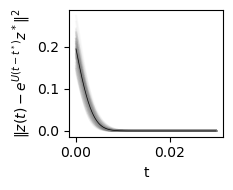

In [37]:
plt.figure(figsize=(2.5,2))

for dev in all_exp_devs:
    plt.plot(times, dev, color='gray', alpha=0.05)
plt.plot(times, np.mean(all_exp_devs, axis=0), "k", linewidth=0.5)
plt.xlabel("t")
plt.ylabel(r"$\|z(t) - e^{U(t - t^*)} z^*\|^2$")
plt.tight_layout()
plt.savefig("./figures/deviation_from_exponential_map.svg", dpi = 300, bbox_inches = "tight")

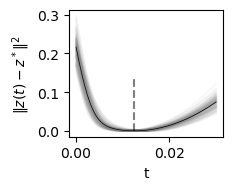

In [36]:
plt.figure(figsize=(2.5,2))

for dev in all_zstar_devs:
    plt.plot(times, dev, color='gray', alpha=0.05)
plt.plot(times, np.mean(all_zstar_devs, axis=0), "k", linewidth=0.5)
plt.vlines(np.mean(all_tstars), ymin = np.min(all_exp_devs) , ymax = np.max(all_exp_devs)*0.5, color='k', linestyle='--', alpha = 0.5)

plt.xlabel("t")
plt.ylabel(r"$\|z(t) - z^*\|^2$")

plt.tight_layout()
plt.savefig("./figures/deviation_from_zstar.svg", dpi = 300, bbox_inches = "tight") 

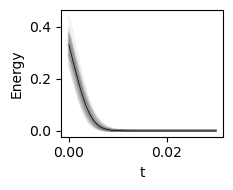

In [35]:
plt.figure(figsize=(2.5,2))
plt.plot(times, np.array(all_energies).T, "gray", alpha=0.05)
plt.plot(times, np.mean(all_energies, axis=0), "k", linewidth=0.5)
plt.xlabel("t")
plt.ylabel("Energy")
plt.tight_layout()
plt.savefig("./figures/energy_decay.svg", dpi = 300, bbox_inches = "tight")